# Tarea 1: Regresión Lineal Simple, Multilineal y Diagnóstico de Modelos
**Máster en Inteligencia Artificial — Curso 2026–2027**

Este cuaderno recoge todos los apartados de la Tarea 1 junto con su **implementación en Python y comprobación empírica** sobre los conjuntos de datos `study_scores.csv` y `apartment_rents.csv`.

### Protocolo Metodológico
* **Aislamiento de `train` y `test`:** Todas las estimaciones OLS, contrastes de hipótesis, cálculos de VIF y análisis de residuos se realizan exclusivamente sobre el subconjunto `train`. El subconjunto `test` se reserva únicamente para evaluar el Error Estándar Residual (RSE) fuera de muestra.
* **Asociación vs. Causalidad:** Todas las relaciones estimadas se interpretan como asociaciones estadísticas y no como relaciones causales.


---
## 2. Fundamentos Teóricos (2 puntos)

### 2.1. Estimación de la pendiente en OLS
El método de **Mínimos Cuadrados Ordinarios (OLS)** busca los parámetros $(\beta_0, \beta_1)$ que minimizan la Suma de los Cuadrados de los Residuos ($\text{RSS}$):
$$\text{RSS}(\beta_0, \beta_1) = \sum_{i=1}^{n} (y_i - \beta_0 - \beta_1 x_i)^2$$

Al ser una función cuadrática convexa, igualamos sus derivadas parciales a cero (ecuaciones normales):
1. $\frac{\partial \text{RSS}}{\partial \beta_0} = -2\sum_{i=1}^n (y_i - \beta_0 - \beta_1 x_i) = 0 \implies \hat{\beta}_0 = \bar{y} - \hat{\beta}_1 \bar{x}$
2. $\frac{\partial \text{RSS}}{\partial \beta_1} = -2\sum_{i=1}^n x_i(y_i - \beta_0 - \beta_1 x_i) = 0$

Sustituyendo $\hat{\beta}_0$ en la segunda ecuación y utilizando que $\sum \bar{x}(y_i - \bar{y}) = 0$ y $\sum \bar{x}(x_i - \bar{x}) = 0$, despejamos la pendiente óptima:
$$\hat{\beta}_1 = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^{n} (x_i - \bar{x})^2} = \frac{\text{Cov}(x, y)}{\text{Var}(x)}$$

### 2.2. Interpretación de las evidencias (1 punto)
A un nivel de significancia del $5\%$ ($\alpha = 0.05$) sobre la Tabla 1 del enunciado:
* **Términos con evidencia de relación no nula ($p < 0.05$):** `constante` ($p < 0.001$), `floor_area_m2` ($p < 0.001$) y `renovated` ($p = 0.004$). En estos tres casos se rechaza $H_0: \beta_j = 0$.
* **Significado del $p$-valor de `bedrooms` ($p = 0.45$):** Indica que, asumiendo que el número de habitaciones no tiene efecto real sobre el alquiler manteniendo constantes el resto de variables ($H_0: \beta_{\text{bedrooms}} = 0$), existe una probabilidad del $45\%$ de observar por puro azar una estimación tan extrema como $19\text{ EUR/mes}$.
* **Uso práctico de la variable:** Al ser $p = 0.45 \gg 0.05$, la variable `bedrooms` no aporta información explicativa adicional relevante una vez controlada la superficie (`floor_area_m2`), por lo que puede eliminarse del modelo para ganar parsimonia.

In [7]:
!pip install numpy pandas statsmodels matplotlib seaborn
# Configuración e importación de librerías
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')

# Carga de los conjuntos de datos
study_df = pd.read_csv('study_scores.csv')
rent_df = pd.read_csv('apartment_rents.csv')

study_train = study_df[study_df['split'] == 'train'].copy()
study_test = study_df[study_df['split'] == 'test'].copy()
rent_train = rent_df[rent_df['split'] == 'train'].copy()
rent_test = rent_df[rent_df['split'] == 'test'].copy()


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


---
## 3. Regresión Lineal Simple: `study_scores.csv` (3 puntos)

### 3.1. Creación del modelo e interpretación (1.25 puntos)
* **Ecuación ajustada (Train):** $\widehat{\text{exam\_score}} = 42.2 + 3.85 \cdot \text{study\_hours}$ (exacto: $42.197 + 3.845 \cdot \text{study\_hours}$).
* **Pendiente ($3.85\text{ puntos/hora}$):** Cada hora adicional de estudio incrementa la calificación esperada en promedio en $3.85\text{ puntos}$.
* **Ordenada en el origen ($42.2\text{ puntos}$):** Puntuación base esperada para $0\text{ horas}$ de estudio.
* **Adecuación del término constante:** El rango observado en `train` va de $1.17\text{ h}$ a $12.0\text{ h}$. Aunque $0\text{ h}$ supone una leve extrapolación, incluir el intercepto es imprescindible; eliminarlo forzaría la recta a pasar por $(0,0)$, distorsionando artificialmente la pendiente.

Dimensiones Train: (80, 4), Test: (20, 4)
Rango study_hours en Train: [1.17, 11.95] horas

                            OLS Regression Results                            
Dep. Variable:             exam_score   R-squared:                       0.875
Model:                            OLS   Adj. R-squared:                  0.873
Method:                 Least Squares   F-statistic:                     545.7
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           5.90e-37
Time:                        13:05:47   Log-Likelihood:                -238.07
No. Observations:                  80   AIC:                             480.1
Df Residuals:                      78   BIC:                             484.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------

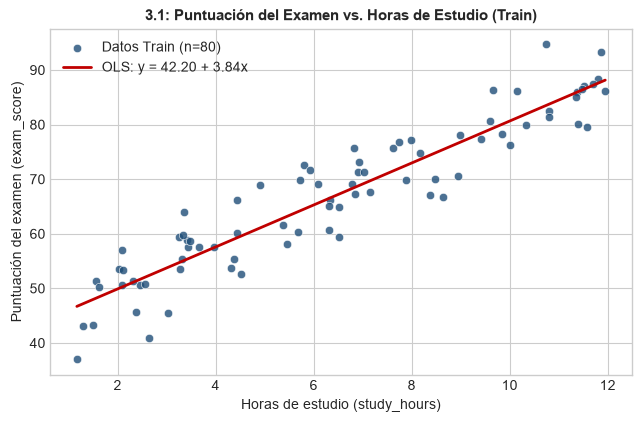

In [8]:
# 3.1 Ajuste OLS y visualización en entrenamiento
modelo_estudio = smf.ols('exam_score ~ study_hours', data=study_train).fit()
print(f"Dimensiones Train: {study_train.shape}, Test: {study_test.shape}")
print(
    f"Rango study_hours en Train: [{study_train['study_hours'].min():.2f}, {study_train['study_hours'].max():.2f}] horas\n")
print(modelo_estudio.summary())

fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.scatterplot(data=study_train, x='study_hours', y='exam_score', color='#1f4e78', alpha=0.8,
                label='Datos Train (n=80)', ax=ax)
x_vals = np.linspace(study_train['study_hours'].min(), study_train['study_hours'].max(), 100)
y_vals = modelo_estudio.params['Intercept'] + modelo_estudio.params['study_hours'] * x_vals
ax.plot(x_vals, y_vals, color='#c00000', linewidth=2,
        label=f'OLS: y = {modelo_estudio.params["Intercept"]:.2f} + {modelo_estudio.params["study_hours"]:.2f}x')
ax.set_title('3.1: Puntuación del Examen vs. Horas de Estudio (Train)', fontsize=11, fontweight='bold')
ax.set_xlabel('Horas de estudio (study_hours)')
ax.set_ylabel('Puntuación del examen (exam_score)')
ax.legend()
plt.show()


### 3.2. Inferencia, análisis de residuos y RSE en test (1.5 puntos)
* **Inferencia sobre la pendiente:** $\hat{\beta}_1 = 3.85\text{ puntos/h}$, con $\text{IC}_{95\%} = [3.52,\; 4.17]\text{ puntos/h}$ y $p\text{-valor} = 5.90 \times 10^{-37} < 0.001$.
* **Coeficiente $R^2 = 0.875$:** Mide la proporción de variabilidad total de las notas explicada por las horas de estudio ($87.5\%$).
* **Limitación del $p$-valor:** Por sí solo solo descarta que la pendiente sea cero, pero no cuantifica la magnitud del error de predicción ni garantiza que se cumplan los supuestos de linealidad, homocedasticidad y normalidad.
* **Diagnóstico y RSE en test:** Los residuos se distribuyen aleatoriamente en torno a cero con varianza constante y el gráfico Q-Q sigue fielmente la diagonal normal. El Error Estándar Residual sobre `test` ($n = 20$) es **$\text{RSE}_{\text{test}} = 5.47\text{ puntos}$**.

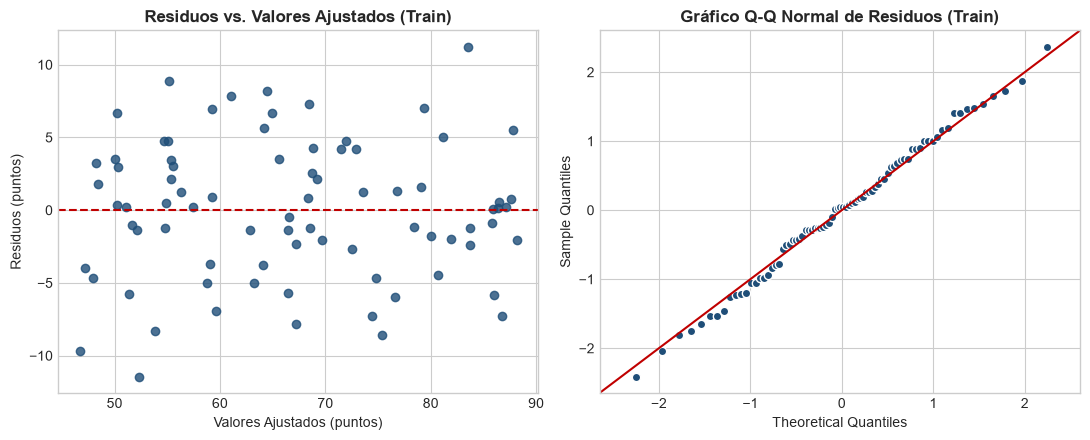

Pendiente estimada: 3.845 puntos/hora
IC 95% Pendiente: [3.517, 4.173] puntos/hora
p-valor pendiente: 5.902e-37
R² (Train): 0.875
RSE en el conjunto Test (n=20): 5.466 puntos


In [9]:
# 3.2 Diagnóstico de residuos, Q-Q plot y cálculo de RSE en test
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(modelo_estudio.fittedvalues, modelo_estudio.resid, color='#1f4e78', alpha=0.8)
axes[0].axhline(0, color='#c00000', linestyle='--', linewidth=1.5)
axes[0].set_title('Residuos vs. Valores Ajustados (Train)', fontweight='bold')
axes[0].set_xlabel('Valores Ajustados (puntos)')
axes[0].set_ylabel('Residuos (puntos)')

sm.qqplot(modelo_estudio.resid, line='45', fit=True, ax=axes[1], markerfacecolor='#1f4e78', markeredgecolor='white')
axes[1].get_lines()[1].set_color('#c00000')
axes[1].set_title('Gráfico Q-Q Normal de Residuos (Train)', fontweight='bold')
plt.tight_layout()
plt.show()

pred_test_estudio = modelo_estudio.predict(study_test)
res_test_estudio = study_test['exam_score'] - pred_test_estudio
rse_test_estudio = np.sqrt(np.sum(res_test_estudio**2) / (len(study_test) - 2))
ci_estudio = modelo_estudio.conf_int(alpha=0.05)
print(f"Pendiente estimada: {modelo_estudio.params['study_hours']:.3f} puntos/hora")
print(f"IC 95% Pendiente: [{ci_estudio.loc['study_hours', 0]:.3f}, {ci_estudio.loc['study_hours', 1]:.3f}] puntos/hora")
print(f"p-valor pendiente: {modelo_estudio.pvalues['study_hours']:.3e}")
print(f"R² (Train): {modelo_estudio.rsquared:.3f}")
print(f"RSE en el conjunto Test (n=20): {rse_test_estudio:.3f} puntos")

### 3.3. Predicción puntual (0.25 puntos)
Para un estudiante con $6.5\text{ horas}$ de estudio, la nota esperada es **$67.2\text{ puntos}$** ($67.189\text{ puntos}$).

In [10]:
# 3.3 Predicción para 6.5 horas de estudio
pred_6_5 = modelo_estudio.predict(pd.DataFrame({'study_hours': [6.5]})).iloc[0]
print(f"Predicción para 6.5 horas de estudio: {pred_6_5:.3f} puntos (67.2 puntos)")

Predicción para 6.5 horas de estudio: 67.189 puntos (67.2 puntos)


---
## 4. Regresión Multilineal: `apartment_rents.csv` (5 puntos)

### 4.1. Análisis exploratorio y correlaciones en entrenamiento (1 punto)
Se reportan la media, mediana, desviación estándar y el rango inter-percentil ($2.5\% - 97.5\%$) en `train` ($n = 135$), así como la matriz de correlaciones de Pearson.

In [11]:
# 4.1 Estadísticos descriptivos y correlaciones (Train)
rent_vars = ['monthly_rent_eur', 'floor_area_m2', 'bedrooms', 'building_age_years', 'distance_center_km', 'renovated']
stats_4_1 = pd.DataFrame({
    'Media': rent_train[rent_vars].mean(),
    'Mediana': rent_train[rent_vars].median(),
    'Desv_Std': rent_train[rent_vars].std(),
    'P2.5': rent_train[rent_vars].quantile(0.025),
    'P97.5': rent_train[rent_vars].quantile(0.975)
})
print("--- Estadísticos Descriptivos (Train, n=135) ---")
print(stats_4_1.round(3))
print("\n--- Matriz de Correlación de Pearson (Train) ---")
print(rent_train[rent_vars].corr().round(3))

--- Estadísticos Descriptivos (Train, n=135) ---
                       Media  Mediana  Desv_Std     P2.5     P97.5
monthly_rent_eur    1295.899  1220.24   434.938  674.564  2271.395
floor_area_m2         80.375    79.50    22.896   39.120   124.490
bedrooms               2.393     2.00     0.915    1.000     4.000
building_age_years    24.119    25.00    13.121    1.350    45.000
distance_center_km     9.316     8.98     4.898    1.401    17.169
renovated              0.407     0.00     0.493    0.000     1.000

--- Matriz de Correlación de Pearson (Train) ---
                    monthly_rent_eur  floor_area_m2  bedrooms  \
monthly_rent_eur               1.000          0.815     0.720   
floor_area_m2                  0.815          1.000     0.904   
bedrooms                       0.720          0.904     1.000   
building_age_years            -0.146         -0.041    -0.049   
distance_center_km            -0.392         -0.079    -0.020   
renovated                      0.018      

### 4.2. Modelo de regresión multilineal (0.75 puntos)
* **Métricas:** $R^2 = 0.819$ en entrenamiento y **$\text{RSE}_{\text{test}} = 196\text{ EUR/mes}$** ($195.87\text{ EUR/mes}$) sobre el conjunto `test` ($n = 45$).
* **Interpretación *ceteris paribus*:**
  * `floor_area_m2`: $+15.3\text{ EUR/mes}$ por cada $\text{m}^2$ adicional.
  * `bedrooms`: $+1.18\text{ EUR/mes}$ por habitación adicional (no significativo, $p = 0.978$).
  * `renovated`: $+161\text{ EUR/mes}$ adicionales si el piso está renovado (`1`) frente a no renovado (`0`).

In [12]:
# 4.2 Ajuste del modelo multilineal y cálculo de RSE en test
formula_mult = 'monthly_rent_eur ~ floor_area_m2 + bedrooms + building_age_years + distance_center_km + renovated'
modelo_mult = smf.ols(formula_mult, data=rent_train).fit()
print(modelo_mult.summary())

pred_test_rent = modelo_mult.predict(rent_test)
res_test_rent = rent_test['monthly_rent_eur'] - pred_test_rent
rse_test_rent = np.sqrt(np.sum(res_test_rent**2) / (len(rent_test) - len(modelo_mult.params)))
print(f"\nR² (Train): {modelo_mult.rsquared:.3f}")
print(f"RSE en Test (Modelo Multilineal, n=45): {rse_test_rent:.3f} EUR/mes")

                            OLS Regression Results                            
Dep. Variable:       monthly_rent_eur   R-squared:                       0.819
Model:                            OLS   Adj. R-squared:                  0.812
Method:                 Least Squares   F-statistic:                     116.8
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           3.81e-46
Time:                        13:12:04   Log-Likelihood:                -895.80
No. Observations:                 135   AIC:                             1804.
Df Residuals:                     129   BIC:                             1821.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept            388.7386     82

### 4.3. Correlación, VIF y contraste sobre `bedrooms` (1.25 puntos)
* **Multicolinealidad (VIF):** `floor_area_m2` ($5.57$) y `bedrooms` ($5.53$) presentan una colinealidad elevada ($r = 0.904$).
* **Regresión simple vs. multilineal:** En regresión simple (`monthly_rent_eur ~ bedrooms`), el coeficiente es $342\text{ EUR/(mes}\cdot\text{hab)}$ ($p = 7.61 \times 10^{-23}$). Al incluir `floor_area_m2` en el modelo multilineal, cae a $1.18\text{ EUR/(mes}\cdot\text{hab)}$ ($p = 0.978$).
* **Conclusión:** Existe asociación marginal positiva (pisos con más habitaciones suelen ser más caros porque son más grandes), pero **no existe asociación condicional**: a igualdad de superficie, el número de habitaciones no encarece el alquiler.

In [13]:
# 4.3 Cálculo de VIF y regresión simple renta vs bedrooms
X_vif = sm.add_constant(rent_train[['floor_area_m2', 'bedrooms', 'building_age_years', 'distance_center_km', 'renovated']])
vif_df = pd.DataFrame({
    'Variable': X_vif.columns[1:],
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])]
})
print("--- Factor de Inflación de la Varianza (VIF) ---")
print(vif_df.round(3).to_string(index=False))

modelo_bed_simple = smf.ols('monthly_rent_eur ~ bedrooms', data=rent_train).fit()
print("\n--- Regresión Simple: monthly_rent_eur ~ bedrooms ---")
print(modelo_bed_simple.summary().tables[1])

--- Factor de Inflación de la Varianza (VIF) ---
          Variable   VIF
     floor_area_m2 5.569
          bedrooms 5.534
building_age_years 1.003
distance_center_km 1.042
         renovated 1.040

--- Regresión Simple: monthly_rent_eur ~ bedrooms ---
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    477.1073     73.240      6.514      0.000     332.242     621.973
bedrooms     342.2196     28.605     11.964      0.000     285.640     398.799


### 4.4. Diagnóstico y 4.5. Nuevo modelo con término cuadrático centrado (1.75 puntos)
* **Diagnóstico (4.4):** Los residuos del modelo lineal frente a `floor_area_m2` muestran un **patrón en forma de 'U'**, violando la **hipótesis de linealidad**.
* **Modelo cuadrático centrado (4.5):** Centramos `floor_area_m2` en su media muestral ($80.4\text{ m}^2$) y añadimos $\text{area\_c}^2$. El **test $F$ anidado** arroja $F = 77.1$ ($p = 9.05 \times 10^{-15}$), el $R^2$ sube de **$0.819$ a $0.887$** y el RSE de entrenamiento baja de **$189$ a $150\text{ EUR/mes}$**, desapareciendo el patrón en U.
* **Alcance de conclusiones:** Podemos afirmar que la relación superficie-alquiler es no lineal (convexa) dentro del rango observado, pero **no** podemos concluir causalidad ni extrapolar fuera del dominio de los datos.

Punto de centrado (media de superficie en train): 80.375 m²

                            OLS Regression Results                            
Dep. Variable:       monthly_rent_eur   R-squared:                       0.887
Model:                            OLS   Adj. R-squared:                  0.882
Method:                 Least Squares   F-statistic:                     167.6
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           4.06e-58
Time:                        13:15:33   Log-Likelihood:                -863.99
No. Observations:                 135   AIC:                             1742.
Df Residuals:                     128   BIC:                             1762.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------

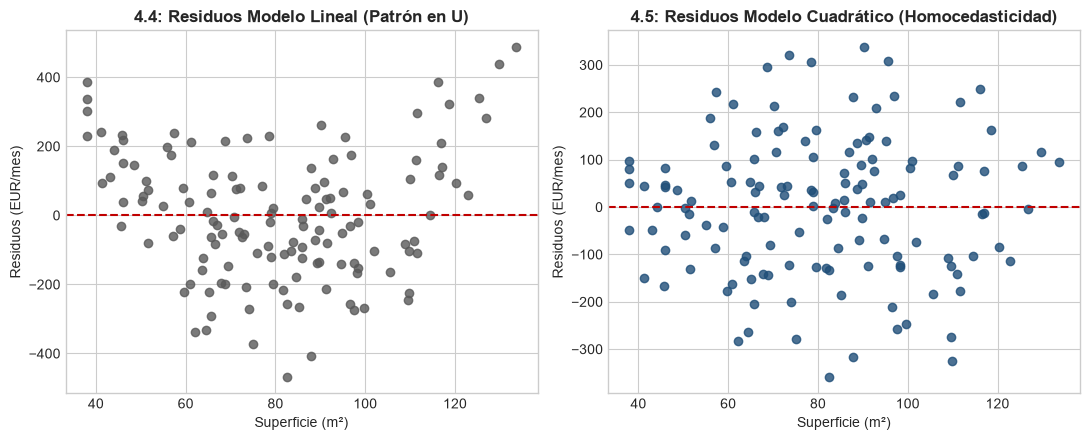

In [14]:
# 4.4 & 4.5 Modelo cuadrático centrado, test F anidado y comparativa de residuos
mean_area = rent_train['floor_area_m2'].mean()
rent_train['area_c'] = rent_train['floor_area_m2'] - mean_area
rent_train['area_c2'] = rent_train['area_c'] ** 2

formula_quad = 'monthly_rent_eur ~ area_c + area_c2 + bedrooms + building_age_years + distance_center_km + renovated'
modelo_quad = smf.ols(formula_quad, data=rent_train).fit()
anova_res = sm.stats.anova_lm(modelo_mult, modelo_quad)

print(f"Punto de centrado (media de superficie en train): {mean_area:.3f} m²\n")
print(modelo_quad.summary())
print("\n--- Test F Anidado (Lineal vs. Cuadrático) ---")
print(anova_res)
print(f"\nComparativa Train:")
print(f"R² Lineal: {modelo_mult.rsquared:.3f}  -->  R² Cuadrático: {modelo_quad.rsquared:.3f}")
print(f"RSE Train Lineal: {np.sqrt(modelo_mult.mse_resid):.3f} EUR/mes  -->  RSE Train Cuadrático: {np.sqrt(modelo_quad.mse_resid):.3f} EUR/mes")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(rent_train['floor_area_m2'], modelo_mult.resid, color='#595959', alpha=0.8)
axes[0].axhline(0, color='#c00000', linestyle='--', linewidth=1.5)
axes[0].set_title('4.4: Residuos Modelo Lineal (Patrón en U)', fontweight='bold')
axes[0].set_xlabel('Superficie (m²)')
axes[0].set_ylabel('Residuos (EUR/mes)')

axes[1].scatter(rent_train['floor_area_m2'], modelo_quad.resid, color='#1f4e78', alpha=0.8)
axes[1].axhline(0, color='#c00000', linestyle='--', linewidth=1.5)
axes[1].set_title('4.5: Residuos Modelo Cuadrático (Homocedasticidad)', fontweight='bold')
axes[1].set_xlabel('Superficie (m²)')
axes[1].set_ylabel('Residuos (EUR/mes)')
plt.tight_layout()
plt.show()

### 4.6. Predicción e intervalo de confianza al 95% (0.25 puntos)
Para un piso de $75\text{ m}^2$, $2\text{ habitaciones}$, $12\text{ años}$ de antigüedad y reformado (`renovated = 1`), fijando `distance_center_km` en su media de entrenamiento ($9.32\text{ km}$):
* **Alquiler mensual predicho:** **$1276\text{ EUR/mes}$** ($1276.32\text{ EUR/mes}$).
* **Intervalo de confianza al 95% (media esperada):** **$[1225,\; 1328]\text{ EUR/mes}$**.

In [16]:
# 4.6 Predicción puntual e intervalo de confianza al 95%
nuevo_piso = pd.DataFrame({
    'area_c': [75.0 - mean_area],
    'area_c2': [(75.0 - mean_area) ** 2],
    'bedrooms': [2],
    'building_age_years': [12],
    'distance_center_km': [rent_train['distance_center_km'].mean()],
    'renovated': [1]
})
pred_ic = modelo_quad.get_prediction(nuevo_piso).summary_frame(alpha=0.05)
print(f"Distancia al centro fijada en la media de train: {rent_train['distance_center_km'].mean():.3f} km\n")
print(pred_ic[['mean', 'mean_ci_lower', 'mean_ci_upper', 'obs_ci_lower', 'obs_ci_upper']].round(3))

Distancia al centro fijada en la media de train: 9.316 km

       mean  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  1276.317       1224.537       1328.097       975.918      1576.716
